In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [3]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Online Payment Fraud Detection/new_data.csv')
print(df.head())
print(df.info())

   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 co

In [4]:
obj = (df.dtypes == 'object')
object_cols = list(obj[obj].index)
print("\nCategorical variables:")
print(object_cols)
print('\nNo. of. categorical features: ', len(object_cols))

int_obj = (df.dtypes == 'int64')
int_obj_cols = list(int_obj[int_obj].index)
print("\nInteger variables:")
print(int_obj_cols)

float_obj = (df.dtypes == 'float64')
float_obj_cols = list(float_obj[float_obj].index)
print("\nFloat variables:")
print(float_obj_cols)


Categorical variables:
['type', 'nameOrig', 'nameDest']

No. of. categorical features:  3

Integer variables:
['step', 'isFraud', 'isFlaggedFraud']

Float variables:
['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


<Axes: xlabel='type', ylabel='count'>

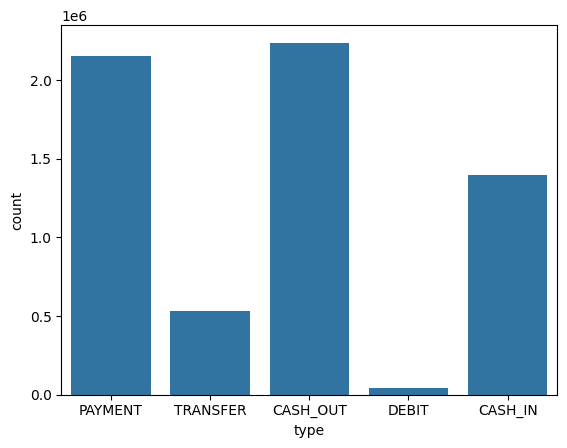

In [5]:
sns.countplot(x='type', data=df)

<Axes: xlabel='type', ylabel='amount'>

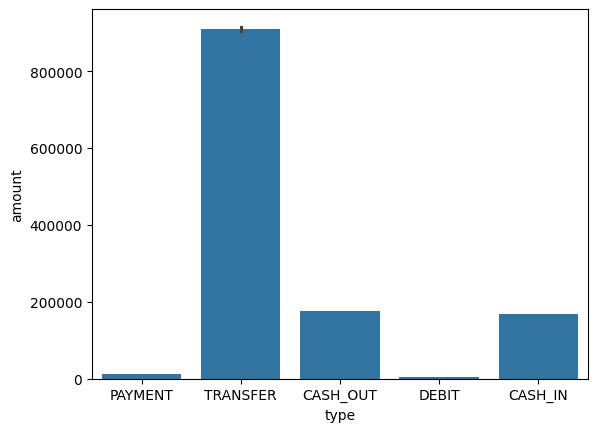

In [6]:
sns.barplot(x='type', y='amount', data=df)

In [7]:
df['isFraud'].value_counts()

,count
isFraud,
0,6354407
1,8213


Text(0, 0.5, 'Frequency')

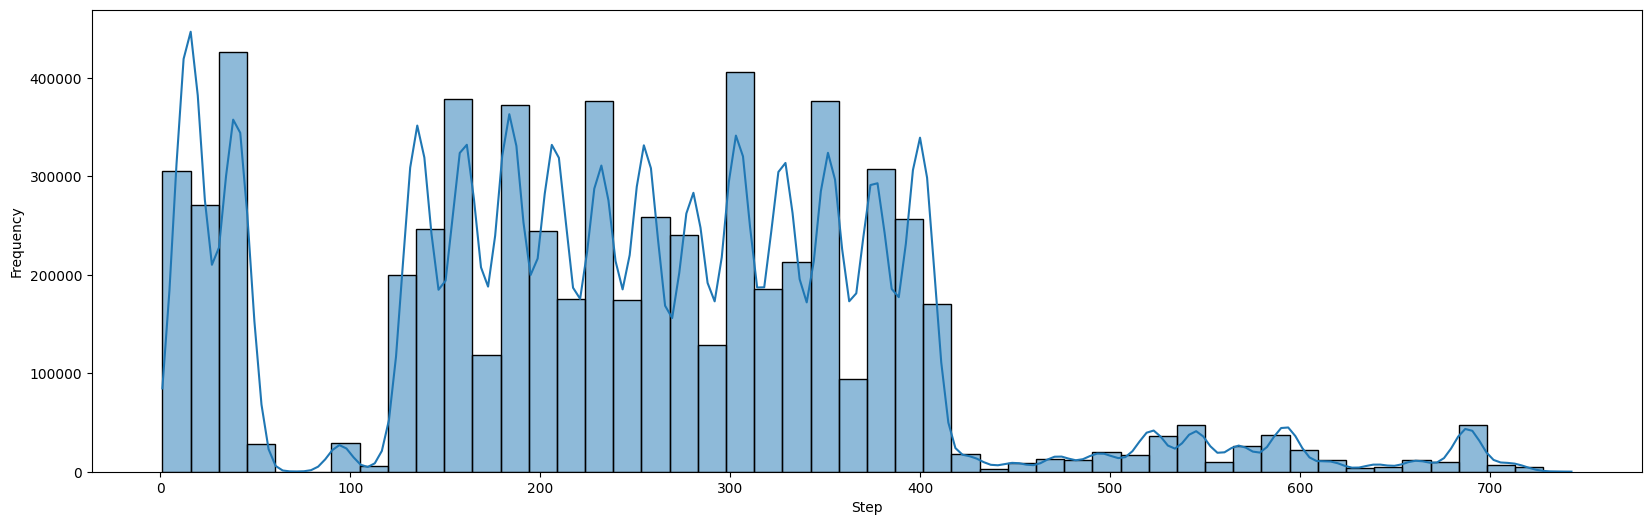

In [8]:
plt.figure(figsize=(20, 6))
sns.histplot(df['step'], kde=True, bins=50)
plt.xlabel('Step')
plt.ylabel('Frequency')

<Axes: >

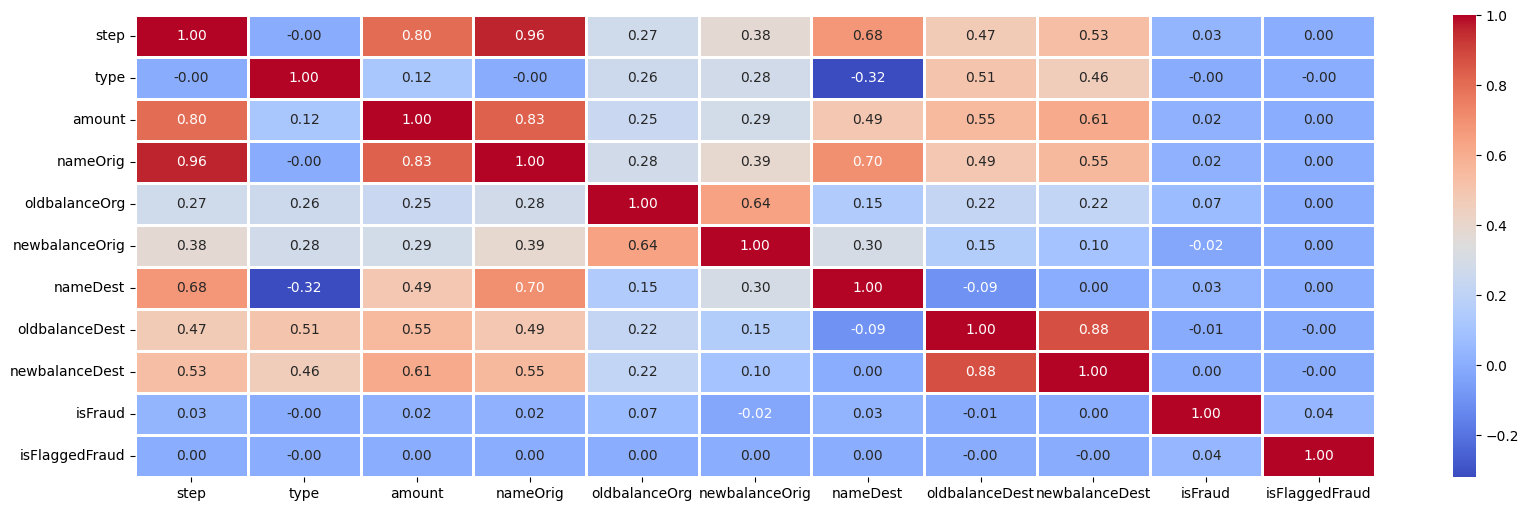

In [9]:
plt.figure(figsize=(20, 6))
sns.heatmap(df.apply(lambda x: pd.factorize(x)[0]).corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=2)

In [10]:
new_type = pd.get_dummies(df['type'], drop_first=True)
new_df = pd.concat([df, new_type], axis=1)
new_df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,CASH_OUT,DEBIT,PAYMENT,TRANSFER
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,False,False,True,False
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,False,False,True,False
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,False,False,False,True
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,True,False,False,False
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,False,False,True,False


In [11]:
X = new_df.drop(['isFraud', 'type', 'nameOrig', 'nameDest'], axis=1)
y = new_df['isFraud']
print(X.shape)
print(y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

(6362620, 11)
(6362620,)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

ROC AUC score:  0.7033746038495938


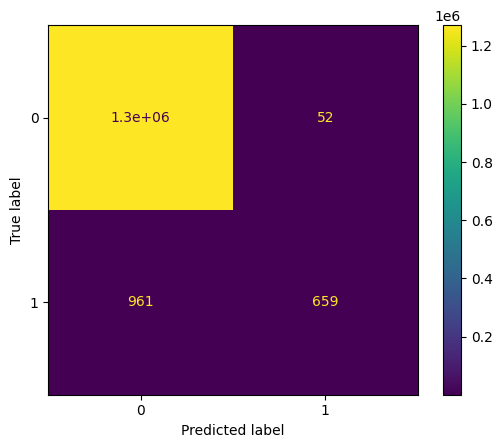

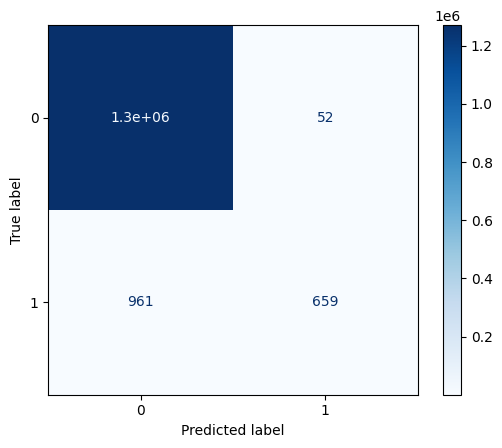

In [ ]:
lr = make_pipeline(StandardScaler(), LogisticRegression())

models = [lr, SVC(), RandomForestClassifier(n_estimators=7, criterion='entropy', random_state=7), XGBClassifier()]

for model in models:
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  print(model)
  print('\nROC AUC score: ', roc_auc_score(y_test, y_pred))

  cm = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
  cm.plot(cmap='Blues')
  plt.show()